# Medir el costo de filtrar propuestas del optimizador

**Pregunta:** ¿El filtro aprendido reduce las evaluaciones exactas del circuito y conserva el punto operativo verificado por el motor?

Nivel: 4. Prerrequisitos: niveles 1–3 de este tema. Lectura: 32 minutos.

## Objetivos

Esta investigación prueba una afirmación de ingeniería concreta: una puntuación aprendida podría ayudar a una búsqueda restringida a usar menos llamadas a su simulador exacto de procesos. Examinarás los registros pareados y comprometidos de todas las variantes optimizadas con filtro, cuantificarás el costo de evaluación y volverás a ejecutar algunos óptimos reportados en el motor del circuito. Un resultado negativo es útil porque el filtro es un componente de optimización cuyo costo debe medirse, no suponerse.

## Preparación

Entorno fijado; instala una vez en el entorno del repositorio con este comando, no dentro del notebook:

```bash
pip install numpy==2.2.6 pandas==2.2.3 matplotlib==3.11.2
```

El notebook solo informa las versiones instaladas y nunca modifica los registros de origen.

## Datos

Los datos principales son registros de escenarios versionados y escritos por el equipo OreFlow en `data/derived/cases/<case_id>.json`, bajo la licencia MIT del repositorio. Los registros contienen la búsqueda con filtro, su contraparte sin filtro con los mismos inicios, las decisiones finales y los conteos de evaluaciones del motor. Los doce casos son escenarios construidos, no observaciones de plantas en operación. Los controles y límites por caso están en `data/derived/contract/operating_contract.json`; el método y sus límites se documentan en `docs/methodologies/12_optimization.md`. Repositorio: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Método

Para cada variante, N_f es el número de evaluaciones distintas del motor exacto que realiza la búsqueda asistida por filtro y N_0 es el conteo de la búsqueda pareada sin filtro. La diferencia es d=N_f-N_0; el costo relativo es 100d/N_0. Un valor negativo de d significaría menos llamadas al simulador. Cero significa que no cambia. Un valor positivo significa más trabajo del simulador. No comparamos semillas, inicios, restricciones u objetivos diferentes: ambos conteos pertenecen al mismo registro de optimización y usan el mismo caso operativo y ponderación. Este emparejamiento controla el escenario y la configuración de búsqueda, pero no convierte los escenarios escritos en una muestra de plantas reales.

El filtro puede ordenar propuestas, pero el motor exacto de procesos evalúa un candidato antes de que pueda reemplazar a un incumbente. Por ello, la comprobación central de integridad no es si el modelo predice una buena puntuación; es si cada óptimo guardado constituye un resultado válido del motor. El código reconstruye los vectores de decisión desde el punto base del catálogo, llama al método de producción `simulate` de OreFlow y compara la tasa de metal pagable recuperado con el registro. También comprueba el residuo máximo de balance que devuelve el motor. Una discrepancia pequeña invalidaría la comparación hasta resolver si hay un registro obsoleto, un método cambiado o un error de reconstrucción.

Las dos figuras responden preguntas distintas. La dispersión pareada muestra si un procedimiento usa sistemáticamente menos evaluaciones; la línea de identidad marca costos iguales. El gráfico por caso muestra cómo un agregado puede ocultar variación entre escenarios de mineral. El número de variantes no equivale al número de minas independientes: varias variantes comparten caso y cambian una entrada controlada. Informamos conteos y diferencias pareadas exactas, en vez de un intervalo de confianza que implicaría un muestreo de población que estos datos no tienen.

## Comparación

La búsqueda es un patrón generalizado con barrera progresiva para las restricciones de ley, potencia y agua. El componente aprendido solo ordena propuestas. El procedimiento de referencia es la misma búsqueda restringida con el filtro desactivado, no otro optimizador escogido para facilitar la comparación. Ambos conservan el motor exacto del circuito como evaluador. Esta distinción importa: una predicción rápida no ahorra cómputo si conduce a más pasos de búsqueda o cambia el punto operativo físico seleccionado.

El beneficio propuesto es reducir llamadas al modelo de procesos, que es costoso. Lo medimos directamente con los conteos pareados comprometidos y después comprobamos los puntos seleccionados con `simulate`. No deducimos una mejora de velocidad a partir del tiempo de inferencia del modelo, de que el filtro haya rechazado candidatos ni de un error pequeño en algunos puntos. Esas cantidades no miden el trabajo total ni demuestran utilidad para una persona operadora.

Registra las versiones fijadas antes de importar los métodos de análisis y de proceso.

In [1]:
# Registra las versiones exactas de las bibliotecas de análisis usadas en esta lección.
import importlib.metadata
for package in ('numpy', 'pandas', 'matplotlib'):
    print(package, importlib.metadata.version(package))

numpy 2.2.6
pandas 2.2.3
matplotlib 3.11.2


Importa las herramientas de análisis y vincúlate al método de circuito de producción de OreFlow.

In [2]:
# Importa las herramientas de análisis y el motor de circuito de producción.
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

repo = Path('../../../').resolve()
sys.path.insert(0, str(repo / 'data-pipeline'))
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case_by_id = {case.id: case for case in CASES}
print('scenario count:', len(case_by_id))
print('engine method:', simulate.__module__ + '.' + simulate.__name__)

scenario count: 12
engine method: pipeline.engine.circuit.simulate


Lee los registros pareados y calcula una fila por variante con filtro; los archivos originales permanecen intactos.

In [3]:
# Carga los registros pareados comprometidos sin modificarlos.
records = []
for path in sorted((repo / 'data/derived/cases').glob('*.json')):
    artifact = json.loads(path.read_text(encoding='utf-8'))
    for variant in artifact['variants']:
        result = variant['methods']['optimization']
        if not result.get('screened') or 'without_screen' not in result:
            continue
        plain = result['without_screen']
        optimum = result.get('optimum') or {}
        records.append({
            'case_id': artifact['case_id'],
            'variant_id': variant['id'],
            'screened_evaluations': result['evaluations'],
            'plain_evaluations': plain['evaluations'],
            'metal_screened_tph': optimum.get('recovered_tph', np.nan),
            'metal_plain_tph': plain.get('recovered_tph', np.nan),
        })
paired = pd.DataFrame(records)
paired['difference'] = paired.screened_evaluations - paired.plain_evaluations
paired['relative_cost_pct'] = 100 * paired.difference / paired.plain_evaluations
print('paired variants:', len(paired))
display(paired.head())

paired variants: 72


,case_id,variant_id,screened_evaluations,plain_evaluations,metal_screened_tph,metal_plain_tph,difference,relative_cost_pct
0,copper_molybdenum,nominal,347,266,3.826023,3.826023,81,30.451128
1,copper_molybdenum,harder_ore,470,368,3.635680,3.635680,102,27.717391
2,copper_molybdenum,coarser_grind,349,267,3.826023,3.826023,82,30.711610
3,copper_molybdenum,higher_throughput,339,269,4.488142,4.488142,70,26.022305
4,copper_molybdenum,more_collector,365,279,3.826023,3.826023,86,30.824373


Reevalúa un óptimo guardado con el motor. El residuo pequeño comprueba reproducibilidad; no valida frente a una planta.

Reconstruye el óptimo reportado de copper porphyry soft desde sus decisiones y compara el resultado del motor con el registro guardado.

In [4]:
# Re-run this saved decision vector through the production circuit engine.
case_id = 'copper_porphyry_soft'
artifact = json.loads((repo / f'data/derived/cases/{case_id}.json').read_text(encoding='utf-8'))
variant = next(v for v in artifact['variants'] if v['methods']['optimization'].get('optimum'))
case = case_by_id[case_id]
optimum = variant['methods']['optimization']['optimum']
operating_point = case.nominal.with_values(**optimum['decisions'])
trace = simulate(case.ore, case.plant, operating_point)
recorded = optimum['recovered_tph']
recomputed = trace.metrics['recovered_primary_tph']
print(case_id, variant['id'], 'recorded:', round(recorded, 6),
      'engine:', round(recomputed, 6), 'balance:', trace.metrics['balance_max_relative_error'])

copper_porphyry_soft nominal recorded: 5.195311 engine: 5.195311 balance: 7.756758198714425e-13


Reconstruye el óptimo reportado de copper oxide desde sus decisiones y compara el resultado del motor con el registro guardado.

In [5]:
# Re-run this saved decision vector through the production circuit engine.
case_id = 'copper_oxide'
artifact = json.loads((repo / f'data/derived/cases/{case_id}.json').read_text(encoding='utf-8'))
variant = next(v for v in artifact['variants'] if v['methods']['optimization'].get('optimum'))
case = case_by_id[case_id]
optimum = variant['methods']['optimization']['optimum']
operating_point = case.nominal.with_values(**optimum['decisions'])
trace = simulate(case.ore, case.plant, operating_point)
recorded = optimum['recovered_tph']
recomputed = trace.metrics['recovered_primary_tph']
print(case_id, variant['id'], 'recorded:', round(recorded, 6),
      'engine:', round(recomputed, 6), 'balance:', trace.metrics['balance_max_relative_error'])

copper_oxide nominal recorded: 5.028551 engine: 5.028551 balance: 2.6829113643355508e-14


Reconstruye el óptimo reportado de gold free milling desde sus decisiones y compara el resultado del motor con el registro guardado.

In [6]:
# Re-run this saved decision vector through the production circuit engine.
case_id = 'gold_free_milling'
artifact = json.loads((repo / f'data/derived/cases/{case_id}.json').read_text(encoding='utf-8'))
variant = next(v for v in artifact['variants'] if v['methods']['optimization'].get('optimum'))
case = case_by_id[case_id]
optimum = variant['methods']['optimization']['optimum']
operating_point = case.nominal.with_values(**optimum['decisions'])
trace = simulate(case.ore, case.plant, operating_point)
recorded = optimum['recovered_tph']
recomputed = trace.metrics['recovered_primary_tph']
print(case_id, variant['id'], 'recorded:', round(recorded, 6),
      'engine:', round(recomputed, 6), 'balance:', trace.metrics['balance_max_relative_error'])

gold_free_milling nominal recorded: 0.000878 engine: 0.000878 balance: 5.647903797067463e-14


Reconstruye el óptimo reportado de nickel sulphide desde sus decisiones y compara el resultado del motor con el registro guardado.

In [7]:
# Re-run this saved decision vector through the production circuit engine.
case_id = 'nickel_sulphide'
artifact = json.loads((repo / f'data/derived/cases/{case_id}.json').read_text(encoding='utf-8'))
variant = next(v for v in artifact['variants'] if v['methods']['optimization'].get('optimum'))
case = case_by_id[case_id]
optimum = variant['methods']['optimization']['optimum']
operating_point = case.nominal.with_values(**optimum['decisions'])
trace = simulate(case.ore, case.plant, operating_point)
recorded = optimum['recovered_tph']
recomputed = trace.metrics['recovered_primary_tph']
print(case_id, variant['id'], 'recorded:', round(recorded, 6),
      'engine:', round(recomputed, 6), 'balance:', trace.metrics['balance_max_relative_error'])

nickel_sulphide nominal recorded: 4.03034 engine: 4.03034 balance: 1.2667902902374115e-12


Reconstruye el óptimo reportado de zinc sulfide desde sus decisiones y compara el resultado del motor con el registro guardado.

In [8]:
# Re-run this saved decision vector through the production circuit engine.
case_id = 'zinc_sulfide'
artifact = json.loads((repo / f'data/derived/cases/{case_id}.json').read_text(encoding='utf-8'))
variant = next(v for v in artifact['variants'] if v['methods']['optimization'].get('optimum'))
case = case_by_id[case_id]
optimum = variant['methods']['optimization']['optimum']
operating_point = case.nominal.with_values(**optimum['decisions'])
trace = simulate(case.ore, case.plant, operating_point)
recorded = optimum['recovered_tph']
recomputed = trace.metrics['recovered_primary_tph']
print(case_id, variant['id'], 'recorded:', round(recorded, 6),
      'engine:', round(recomputed, 6), 'balance:', trace.metrics['balance_max_relative_error'])

zinc_sulfide nominal recorded: 35.629143 engine: 35.629143 balance: 9.528764163574008e-14


## Evidencia

El registro fijo de la versión incluye 72 variantes en modo objetivo filtradas, distribuidas entre doce casos escritos. Los conteos agregados son 26.367 evaluaciones del motor con filtro y 22.487 sin filtro. Por lo tanto, el filtro añade 3.880 evaluaciones, un aumento de 17,25 % respecto del conteo sin filtro. Ahorra evaluaciones en cero variantes, cuesta más en 68 y deja cuatro iguales. La comparación es pareada dentro de cada variante; las figuras conservan ese emparejamiento en vez de ocultarlo en un promedio.

Los mismos registros tienen el mismo resultado terminal en 65 variantes: 63 vectores de decisión factibles idénticos y dos resultados no factibles coincidentes. Siete de las 70 parejas factibles seleccionan decisiones diferentes; la mayor diferencia de metal recuperado es 0,002653 t/h (0,017 %). En 5.811 propuestas filtradas, el error absoluto medio de predicción es 0,71 puntos porcentuales, la mediana 0,48 y el máximo 38,16. Volver a ejecutar óptimos seleccionados es una comprobación de integridad separada, no una segunda comparación de rendimiento. El resultado se limita a los escenarios construidos comprometidos y a los ajustes registrados.

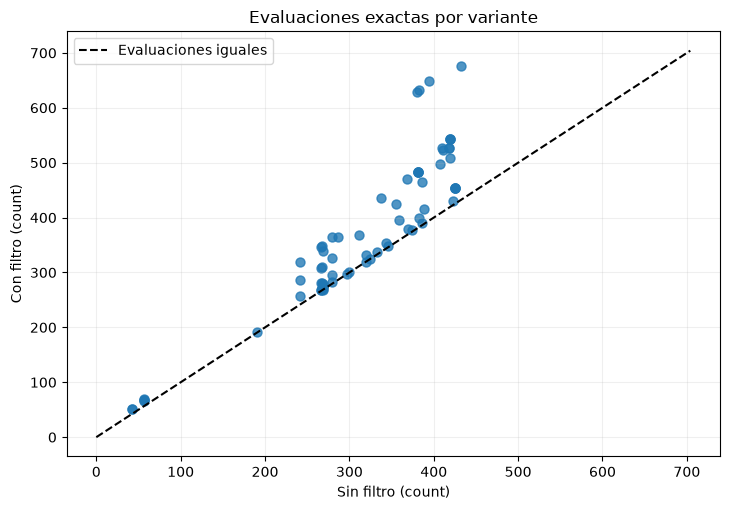

In [9]:
# Plot the paired exact-engine counts for every screened variant.
fig, ax = plt.subplots(figsize=(7.4, 5.2))
ax.scatter(paired.plain_evaluations, paired.screened_evaluations, alpha=0.78, s=42)
limit = max(paired.plain_evaluations.max(), paired.screened_evaluations.max()) * 1.04
ax.plot([0, limit], [0, limit], color='black', linestyle='--', label='Evaluaciones iguales')
ax.set(xlabel='Sin filtro (count)', ylabel='Con filtro (count)')
ax.set_title('Evaluaciones exactas por variante')
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()

Los puntos sobre la línea de identidad discontinua requieren más evaluaciones exactas del circuito con el filtro. Un punto bajo la línea ahorra evaluaciones en esa variante pareada. Lee la distribución junto con el total: ponderar por igual las variantes es transparente, pero los casos fueron construidos y no muestreados de plantas en operación. El gráfico describe solo esta corrida comprometida del algoritmo.

Resume los cambios pareados por escenario de mineral para mostrar la variación que oculta el total.

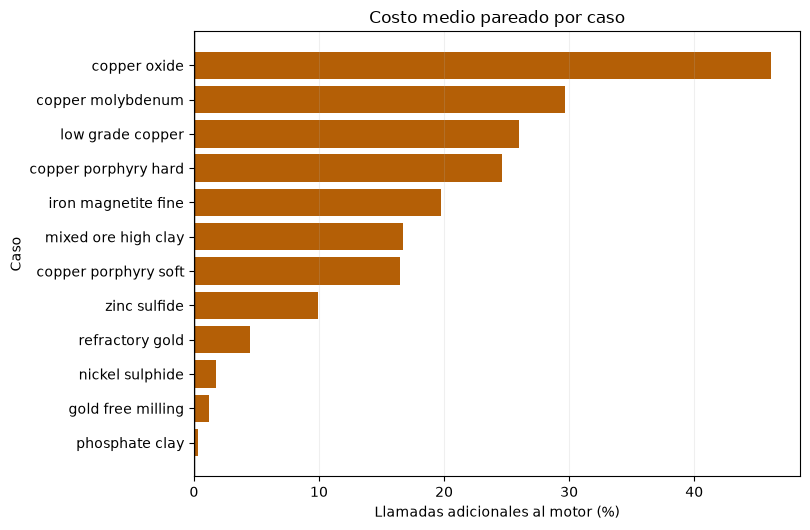

In [10]:
# Summarize the paired evaluation difference within each authored case.
by_case = paired.groupby('case_id', as_index=False).agg(
    mean_relative_cost_pct=('relative_cost_pct', 'mean'),
    variants=('variant_id', 'count'))
by_case = by_case.sort_values('mean_relative_cost_pct')
fig, ax = plt.subplots(figsize=(8.2, 5.4))
colors = np.where(by_case.mean_relative_cost_pct > 0, '#b45f06', '#2878a0')
ax.barh(by_case.case_id.str.replace('_', ' '), by_case.mean_relative_cost_pct, color=colors)
ax.axvline(0, color='black', linewidth=1)
ax.set(xlabel='Llamadas adicionales al motor (%)', ylabel='Caso')
ax.set_title('Costo medio pareado por caso')
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()

Una barra positiva indica que el filtro aumentó el conteo medio de llamadas al motor exacto entre las variantes controladas del caso; una barra negativa indicaría menos llamadas. Las barras son resúmenes descriptivos, no estimaciones independientes. Las variantes de un caso comparten mineral, definición de planta y la mayoría de los parámetros operativos. Esta vista ayuda a detectar patrones de costo por caso sin afirmar frecuencias industriales.

Calcula los totales pareados y cuenta cuántas variantes ahorran o añaden llamadas al motor.

In [11]:
# Sum the paired counts and report the direction of every variant.
screen_total = int(paired.screened_evaluations.sum())
plain_total = int(paired.plain_evaluations.sum())
delta_total = screen_total - plain_total
relative_total = 100 * delta_total / plain_total
print('total con filtro:', screen_total)
print('untotal con filtro:', plain_total)
print('evaluaciones adicionales:', delta_total)
print('aumento relativo (%):', round(relative_total, 1))
print('variantes con menos evaluaciones:', int((paired.difference < 0).sum()))
print('variantes con más evaluaciones:', int((paired.difference > 0).sum()))
print('variantes sin cambio:', int((paired.difference == 0).sum()))

total con filtro: 26367
untotal con filtro: 22487
evaluaciones adicionales: 3880
aumento relativo (%): 17.3
variantes con menos evaluaciones: 0
variantes con más evaluaciones: 68
variantes sin cambio: 4


## Resultados

**Respuesta:** El filtro no reduce el trabajo del motor exacto en las 72 variantes pareadas de esta versión: usa 26.367 evaluaciones frente a 22.487 sin filtro, un aumento de 17,25 %. Cuesta más en 68 variantes, empata en cuatro y no ahorra en ninguna. El resultado terminal coincide en 65 variantes (63 decisiones factibles idénticas y dos resultados no factibles coincidentes); siete parejas factibles difieren. En 5.811 propuestas, el error absoluto medio es 0,71 puntos, la mediana 0,48 y el máximo 38,16. El resultado se limita a escenarios construidos y ajustes comprometidos; no establece el comportamiento con datos medidos de planta ni otros diseños de búsqueda.

## Resumen

El filtro solo pretende ordenar propuestas; el motor del circuito sigue siendo responsable de cada resultado físico. El registro medido responde directamente la pregunta de costo y entrega un resultado negativo: el filtro añade evaluaciones exactas en esta suite de escenarios. Mantén ese hallazgo visible al describir el optimizador. Cualquier revisión futura del filtro necesita un experimento pareado nuevo, la misma comprobación con el motor y una ejecución fresca del notebook; no puede heredar de este resultado una afirmación de velocidad.

## Referencias

- Torczon (1997), On the convergence of pattern search algorithms. https://doi.org/10.1137/S1052623493250780
- Audet y Dennis (2006), Mesh adaptive direct search algorithms for constrained optimization. https://doi.org/10.1137/040603371
- Audet y Dennis (2009), A progressive barrier for derivative-free nonlinear programming. https://doi.org/10.1137/070692662
- Booker et al. (1999), A rigorous framework for optimization of expensive functions by surrogates. https://doi.org/10.1007/BF01197708
- Método de optimización restringida y registros medidos de OreFlow: `docs/methodologies/12_optimization.md` y `data/derived/cases/`.